# Spatial smoothing of your real video fMRI data — one subject

This notebook uses your supplied Lustre paths. There is no demo mode, synthetic dataset or simulated image. Run it on the cluster where those paths are mounted, using your Python notebook kernel.

**Workflow:** inspect available subjects/tasks → select one subject and video tasks → smooth one run → inspect spatial slices and time courses → optionally smooth remaining selected video runs for that subject.

Your subject ID and video task labels were not supplied, so the notebook first lists the actual labels and asks you to enter them. It never chooses a subject or task silently. All outputs are written under your requested output root; source files remain unchanged.

Gaussian smoothing is spatial, independently at every time point. The example FWHM is **4 mm**; this is configurable and is not a validated optimum for infant data. This notebook does not perform motion correction, registration, temporal filtering or ISC.

## 1. Dependencies
Run this cell if packages are missing. If the cluster cannot access the package index, install them in your environment beforehand. Restart the kernel after installation if necessary.

In [ ]:
%pip install -q nilearn pybids nibabel numpy pandas matplotlib

In [ ]:
from pathlib import Path
import json
import time
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from bids import BIDSLayout
from bids.layout import BIDSLayoutIndexer
from nilearn.image import smooth_img
from IPython.display import display

versions = {name: importlib.metadata.version(name)
            for name in ['nilearn', 'pybids', 'nibabel', 'numpy']}
print(versions)

{'nilearn': '0.14.0', 'pybids': '0.22.0', 'nibabel': '5.4.2', 'numpy': '1.26.4'}


## 2. Configuration — your paths are already entered
Leave `SUBJECT` and `VIDEO_TASKS` as `None` on the first pass and run section 3 to see actual labels. Then fill both fields, rerun this configuration cell and continue to section 4 (the index from section 3 can be reused).

Use the subject label without `sub-`. Video tasks must match the BIDS `task-` values exactly. `SESSION=None` and `RUN=None` select every matching session/run for this one subject. Use `EXTRA_FILTERS` to choose a space, description, acquisition or echo if multiple versions exist. Only one selected run is processed initially.

`PRESERVE_ZERO_BACKGROUND=True` resets voxels that were zero at every time point to zero after smoothing. This preserves the existing support of your brain-masked data; it does **not** normalize the Gaussian kernel at mask boundaries. Boundary voxels can still be attenuated by zero background. Turn it off if you want ordinary unrestricted Gaussian output.

In [37]:
DATA_ROOT = Path('/lustre/disk/home/shared/cusacklab/foundcog/bids/derivatives/faizan_motion_correction_dataset/brain_masked_cropped_hfiltered_normalized_to_common_space')
OUTPUT_ROOT = Path('/lustre/disk/home/users/mfaizan/motion_correction/prototyping/motion_aretefacts_correction_cycle_gans_updated/notebooks/spatail_smootting')

SUBJECT = 'XXXXX'         # Label from section 3, without 'sub-' or '_subject_id_'
VIDEO_TASKS = ['videos']   # Task labels in this dataset: 'videos', 'rest10'
SESSION = None
RUN = None
EXTRA_FILTERS = {}         # Example: {'space': 'NIHPD', 'desc': 'preproc'}
FWHM_MM = 8.0              # Millimetres, not voxels
FIRST_RUN_INDEX = 0
PREVIEW_VOLUME = 5         # Zero-based volume index
PRESERVE_ZERO_BACKGROUND = True
RUN_REMAINING_VIDEO_RUNS = False
OVERWRITE = False

## 3. Inspect your real dataset
This cell scans filenames and builds an inventory; it does not load the 4D image arrays. Metadata indexing is disabled to reduce overhead. Only the supplied input directory is indexed, without automatically adding other derivative pipelines.

`validate=False` permits indexing BIDS-like derivative filenames. This is not a BIDS validator and does not certify compliance. A missing dataset description does not trigger creation of any file in your input directory. If no BOLD files are found, check the path and filename suffixes rather than renaming files blindly.

In [38]:
DATA_ROOT = DATA_ROOT.expanduser().resolve()
OUTPUT_ROOT = OUTPUT_ROOT.expanduser().resolve()
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f'Input not accessible: {DATA_ROOT}. Run on the cluster with Lustre mounted.')
if OUTPUT_ROOT == DATA_ROOT or DATA_ROOT in OUTPUT_ROOT.parents:
    raise ValueError('This notebook requires an output directory outside the input directory.')
layout = BIDSLayout(str(DATA_ROOT), validate=False, derivatives=False,
                    config=['bids', 'derivatives'],
                    indexer=BIDSLayoutIndexer(validate=False, index_metadata=False))
all_bold = layout.get(suffix='flirt', extension=['.nii', '.nii.gz'], return_type='object')
if not all_bold:
    raise ValueError('No *_bold_mcf_corrected_flirt.nii[.gz] files indexed. Check your BIDS-like filenames.')
inventory = pd.DataFrame([{
    'subject': f.entities.get('subject'), 'session': f.entities.get('session'),
    'task': f.entities.get('task'), 'run': f.entities.get('run'),
    'space': f.entities.get('space'), 'desc': f.entities.get('desc'),
    'path': f.path} for f in all_bold])
print('Subjects:', sorted(inventory['subject'].dropna().unique()))
print('Tasks:', sorted(inventory['task'].dropna().unique()))
display(inventory.groupby(['subject', 'task'], dropna=False).size().reset_index(name='n_files'))
print('Now set SUBJECT and VIDEO_TASKS in section 2. Rerun section 2, then section 4.')

Subjects: ['ICC103', 'ICC103A', 'ICC105', 'ICC105A', 'ICC107', 'ICC107A', 'ICC111', 'ICC111A', 'ICC113', 'ICC113A', 'ICC115', 'ICC117', 'ICC123', 'ICC125', 'ICC127', 'ICC127A', 'ICC131', 'ICC133', 'ICC133A', 'ICC135', 'ICC139', 'ICC139A', 'ICC141', 'ICC145', 'ICC145A', 'ICC147', 'ICC149', 'ICC151', 'ICC153', 'ICC155', 'ICC155A', 'ICC157', 'ICC159', 'ICC161', 'ICC163', 'ICC165', 'ICC167', 'ICC169', 'ICC177', 'ICC179', 'ICC179A', 'ICC183', 'ICC183A', 'ICC185', 'ICC187', 'ICC189', 'ICC191', 'ICC191A', 'ICC193', 'ICC193A', 'ICC195', 'ICC197', 'ICC199', 'ICC201', 'ICC201A', 'ICC203', 'ICC205', 'ICC205A', 'ICC207', 'ICC211', 'ICC213', 'ICC217', 'ICC221', 'ICC221A', 'ICC223', 'ICC225', 'ICC227', 'ICC229', 'ICC23', 'ICC233', 'ICC235', 'ICC237', 'ICC239', 'ICC239A', 'ICC241', 'ICC241A', 'ICC243', 'ICC243A', 'ICC253', 'ICC255', 'ICC257', 'ICC257A', 'ICC37', 'ICC43', 'ICC43A', 'ICC47', 'ICC51', 'ICC51A', 'ICC53', 'ICC53A', 'ICC55', 'ICC57', 'ICC57A', 'ICC59', 'ICC59A', 'ICC63', 'ICC7', 'ICC75', '

,subject,task,n_files
0,ICC103,videos,4
1,ICC103A,rest10,1
2,ICC103A,videos,2
3,ICC105,rest10,1
4,ICC105,videos,3
...,...,...,...
306,IRN74,videos,1
307,IRN76,rest10,1
308,IRN76,videos,1
309,IRN78,videos,3


Now set SUBJECT and VIDEO_TASKS in section 2. Rerun section 2, then section 4.


## 4. Select video runs for one subject
Check this table before processing. A task label might encode a movie order or might be shared across orders: use the actual filenames in your dataset. This notebook selects by those entities, not by guessing which content is a video. Other subjects and unselected tasks are excluded.

In [39]:
print('SUBJECT:', SUBJECT, '| VIDEO_TASKS:', VIDEO_TASKS)
available_subjects = sorted(inventory['subject'].dropna().unique())
available_tasks = sorted(inventory['task'].dropna().unique())
if SUBJECT not in available_subjects:
    raise ValueError(f'Set SUBJECT in section 2 (without sub-) and rerun it. Available: {available_subjects}')
if not isinstance(VIDEO_TASKS, list) or not VIDEO_TASKS or not set(VIDEO_TASKS) <= set(available_tasks):
    raise ValueError(f'Set VIDEO_TASKS in section 2 to a list of task labels and rerun it. Available: {available_tasks}')
if not np.isfinite(FWHM_MM) or FWHM_MM <= 0:
    raise ValueError('FWHM_MM must be positive and finite.')
query = dict(subject=SUBJECT, task=VIDEO_TASKS, suffix='flirt',
             extension=['.nii', '.nii.gz'], return_type='object')
if SESSION is not None: query['session'] = SESSION
if RUN is not None: query['run'] = RUN
if set(EXTRA_FILTERS) & (set(query) | {'subject', 'task', 'session', 'run', 'return_type'}):
    raise ValueError('Use dedicated configuration fields for subject/task/session/run.')
query.update(EXTRA_FILTERS)
selected_files = sorted(layout.get(**query), key=lambda f: f.path)
if not selected_files:
    raise ValueError('No matching files. Check subject, task labels and other filters.')
assert all(f.entities.get('subject') == SUBJECT for f in selected_files)
assert all(f.entities.get('task') in VIDEO_TASKS for f in selected_files)
selected_table = pd.DataFrame([{
    'index': i, 'session': f.entities.get('session'), 'task': f.entities.get('task'),
    'run': f.entities.get('run'), 'space': f.entities.get('space'),
    'filename': Path(f.path).name} for i, f in enumerate(selected_files)])
display(selected_table)
if not 0 <= FIRST_RUN_INDEX < len(selected_files):
    raise ValueError('FIRST_RUN_INDEX is outside the selected table.')
first_path = Path(selected_files[FIRST_RUN_INDEX].path)
print('First selected file:', first_path)

SUBJECT: ICC97A | VIDEO_TASKS: ['videos']


,index,session,task,run,space,filename
0,0,1,videos,1,None,sub-ICC97A_ses-1_task-videos_dir-AP_run-001_bo...
1,1,1,videos,2,None,sub-ICC97A_ses-1_task-videos_dir-AP_run-002_bo...


First selected file: /lustre/disk/home/shared/cusacklab/foundcog/bids/derivatives/faizan_motion_correction_dataset/brain_masked_cropped_hfiltered_normalized_to_common_space/_subject_id_ICC97A/_referencetype_standard/_run_001_session_1_task_name_videos/sub-ICC97A_ses-1_task-videos_dir-AP_run-001_bold_mcf_corrected_flirt.nii.gz


## 5. Inspect the first run's dimensions and units
A BOLD run must be 4D: `(X, Y, Z, time)`. Smoothing preserves this shape, voxel geometry and temporal sampling. This tutorial requires millimetre spatial units in the NIfTI header. If units are missing, investigate the header using acquisition information rather than assuming units.

One full run is loaded into memory during processing. Actual memory use is several times the single-array size below; the remaining-run loop processes one run at a time.

In [40]:
first_img = nib.load(first_path)
if first_img.ndim != 4:
    raise ValueError(f'Expected 4D BOLD; found {first_img.shape}')
print('Shape:', first_img.shape)
print('Voxel sizes (affine units):', nib.affines.voxel_sizes(first_img.affine))
print('Header zooms (including temporal spacing):', first_img.header.get_zooms())
print('Spatial/time units:', first_img.header.get_xyzt_units())
print('One float32 array (MiB):', round(np.prod(first_img.shape)*4/2**20, 1))

Shape: (60, 72, 56, 485)
Voxel sizes (affine units): [2. 2. 2.]
Header zooms (including temporal spacing): (2.0, 2.0, 2.0, 0.61)
Spatial/time units: ('mm', 'sec')
One float32 array (MiB): 447.6


## 6. Reusable smoothing function
This function reads one real run, rejects NaN/Inf, applies a 3D Gaussian filter at every time point, and saves a float32 image in a separate directory. It also copies coordinate transforms and header timing.

The output path includes `fwhm-<value>mm` and mirrors the source subject/session folders. Each output has `desc-smoothed` and a JSON record containing the source path, settings and software versions. Adjacent source JSON metadata are retained when present; metadata inherited from parent folders are not automatically copied. Original source metadata remain available with the input.

The existing brain support is estimated as voxels nonzero at **any** time point. This avoids using the time average, which may be near zero in filtered/normalized data. It is not a replacement for an independently verified brain mask. Inspect the support count and plots.

Existing output files raise an error unless `OVERWRITE=True`. No synthetic images or test datasets are generated.

In [41]:
def output_path_for(source_path, data_root, output_root, fwhm_mm):
    source_path = Path(source_path).resolve()
    relative = source_path.relative_to(Path(data_root).resolve())
    stem = source_path.name[:-7] if source_path.name.endswith('.nii.gz') else source_path.stem
    stem = stem.removesuffix('_mcf_corrected_flirt')
    parts = [p for p in stem.split('_') if not p.startswith('desc-')]
    if parts[-1] != 'bold':
        raise ValueError('Expected filename ending in _bold_mcf_corrected_flirt.nii[.gz]')
    filename = '_'.join(parts[:-1] + ['desc-smoothed', 'bold']) + '.nii.gz'
    return Path(output_root) / f'fwhm-{fwhm_mm:g}mm' / relative.parent / filename


def smooth_one_run(source_path, data_root, output_root, fwhm_mm,
                   preserve_zero_background=True, overwrite=False):
    source_path = Path(source_path).resolve()
    destination = output_path_for(source_path, data_root, output_root, fwhm_mm)
    sidecar = destination.with_name(destination.name[:-7] + '.json')
    if source_path == destination.resolve():
        raise ValueError('Cannot overwrite the source.')
    if not overwrite and (destination.exists() or sidecar.exists()):
        raise FileExistsError(f'Output exists: {destination}. Use a new output directory or explicitly enable OVERWRITE.')
    if not np.isfinite(fwhm_mm) or fwhm_mm <= 0:
        raise ValueError('FWHM must be positive and finite.')
    img = nib.load(source_path)
    if img.ndim != 4:
        raise ValueError('Expected a 4D BOLD image.')
    if img.header.get_xyzt_units()[0] != 'mm':
        raise ValueError('Verify NIfTI spatial units: this tutorial requires mm.')
    start = time.perf_counter()
    values = img.get_fdata(dtype=np.float32)
    if not np.isfinite(values).all():
        raise ValueError('Input contains NaN/Inf; investigate before smoothing.')
    support = np.any(values != 0, axis=3)
    if not support.any():
        raise ValueError('Input is entirely zero.')
    working = nib.Nifti1Image(values, img.affine, img.header.copy())
    smoothed = smooth_img(working, fwhm=float(fwhm_mm)).get_fdata(dtype=np.float32)
    if preserve_zero_background:
        smoothed[~support, :] = 0
    if not np.isfinite(smoothed).all():
        raise ValueError('Output contains non-finite values.')
    header = img.header.copy()
    header.set_data_dtype(np.float32)
    result = nib.Nifti1Image(smoothed, img.affine, header)
    for getter, setter in [('get_qform', 'set_qform'), ('get_sform', 'set_sform')]:
        matrix, transform_code = getattr(img, getter)(coded=True)
        getattr(result, setter)(matrix, int(transform_code))
    result.header.set_zooms(img.header.get_zooms())
    result.header.set_xyzt_units(*img.header.get_xyzt_units())
    destination.parent.mkdir(parents=True, exist_ok=True)
    nib.save(result, destination)
    adjacent_json = source_path.with_name(
        (source_path.name[:-7] if source_path.name.endswith('.nii.gz') else source_path.stem) + '.json')
    metadata = json.loads(adjacent_json.read_text()) if adjacent_json.exists() else {}
    metadata['SpatialSmoothing'] = {
        'Method': 'Gaussian', 'FWHMmm': float(fwhm_mm),
        'PreserveZeroBackground': preserve_zero_background,
        'MaskBoundaryNormalization': False, 'TemporalSmoothing': False,
        'SourceFile': str(source_path.relative_to(Path(data_root).resolve())),
        'Versions': versions}
    sidecar.write_text(json.dumps(metadata, indent=2))
    return {'source': str(source_path), 'output': str(destination),
            'fwhm_mm': fwhm_mm, 'n_volumes': img.shape[3],
            'support_voxels': int(support.sum()),
            'seconds': round(time.perf_counter() - start, 3)}

## 7. Smooth the first selected video run
This is the first cell that processes image values. The output root is exactly the one you supplied; smoothed images are placed in its FWHM subfolder. The generated dataset description identifies that subfolder as a derivative dataset. This is a BIDS-like output layout, not a claim of complete BIDS validation.

In [42]:
run_output_root = OUTPUT_ROOT / f'fwhm-{FWHM_MM:g}mm'
run_output_root.mkdir(parents=True, exist_ok=True)
description_path = run_output_root / 'dataset_description.json'
if not description_path.exists():
    source_description_path = DATA_ROOT / 'dataset_description.json'
    source_description = json.loads(source_description_path.read_text()) if source_description_path.exists() else {}
    description_path.write_text(json.dumps({
        'Name': 'Spatially smoothed video fMRI',
        'BIDSVersion': source_description.get('BIDSVersion', '1.10.0'),
        'DatasetType': 'derivative',
        'GeneratedBy': [{'Name': 'NilearnSpatialSmoothingNotebook', 'Version': '1.1'}]
    }, indent=2))
first_record = smooth_one_run(first_path, DATA_ROOT, OUTPUT_ROOT, FWHM_MM,
                              preserve_zero_background=PRESERVE_ZERO_BACKGROUND,
                              overwrite=OVERWRITE)
records = [first_record]
smoothed_path = Path(first_record['output'])
display(pd.DataFrame(records))

,source,output,fwhm_mm,n_volumes,support_voxels,seconds
0,/lustre/disk/home/shared/cusacklab/foundcog/bi...,/lustre/disk/home/users/mfaizan/motion_correct...,8.0,485,113172,12.009


## 8. Check the real saved output
These checks use your actual source/output pair. They verify shape, affine, TR/units, coordinate transforms, finite values and (when requested) preserved zero background. They do not determine the scientifically best FWHM. The spatial-only filtering property follows from Nilearn's documented implementation.

In [43]:
after_img = nib.load(smoothed_path)
before = first_img.get_fdata(dtype=np.float32)
after = after_img.get_fdata(dtype=np.float32)
assert first_img.shape == after_img.shape, 'Image shape changed'
assert np.allclose(first_img.affine, after_img.affine), 'Affine changed'
assert np.allclose(first_img.header.get_zooms(), after_img.header.get_zooms()), 'Voxel sizes/TR changed'
assert first_img.header.get_xyzt_units() == after_img.header.get_xyzt_units(), 'Units changed'
for getter in ['get_qform', 'get_sform']:
    old_matrix, old_code = getattr(first_img, getter)(coded=True)
    new_matrix, new_code = getattr(after_img, getter)(coded=True)
    assert old_code == new_code
    if old_matrix is not None:
        assert np.allclose(old_matrix, new_matrix)
assert np.isfinite(after).all()
brain_support = np.any(before != 0, axis=3)
if PRESERVE_ZERO_BACKGROUND:
    assert np.all(after[~brain_support, :] == 0)
print('PASS: output geometry, timing, transforms and finite values.')
print('Brain-support voxels:', int(brain_support.sum()))
print('Mean absolute change inside support:', float(np.mean(np.abs(after[brain_support] - before[brain_support]))))

PASS: output geometry, timing, transforms and finite values.
Brain-support voxels: 113172
Mean absolute change inside support: 32.8591423034668


## 9. Compare spatial slices and a voxel time course
Filtered, normalized fMRI may have a near-zero mean, so the displayed volume is selected directly rather than plotting the temporal mean. The slice contains the most support voxels; the time-course voxel is chosen inside that support near its centre.

Both image panels use identical intensity limits. These are array-coordinate views, not a clinical/radiological orientation display. A voxel's time course can change because it now includes nearby spatial signals; neighbouring time points are not averaged.

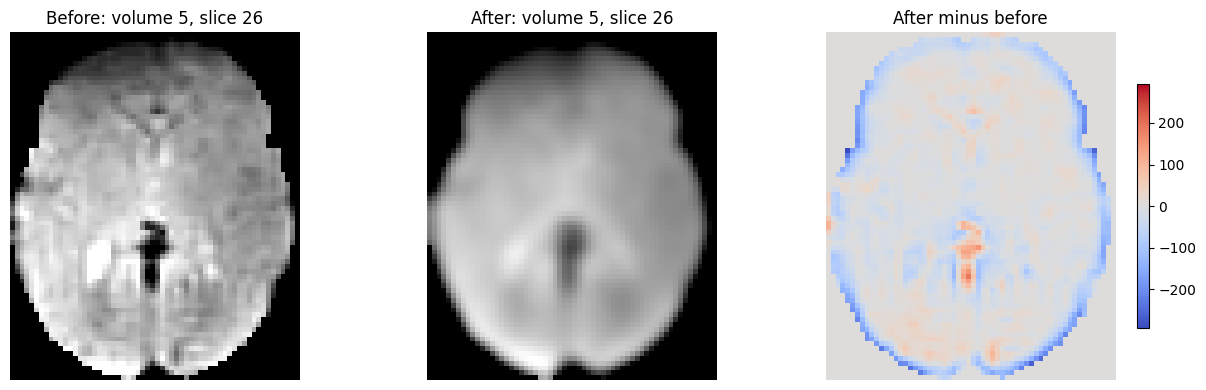

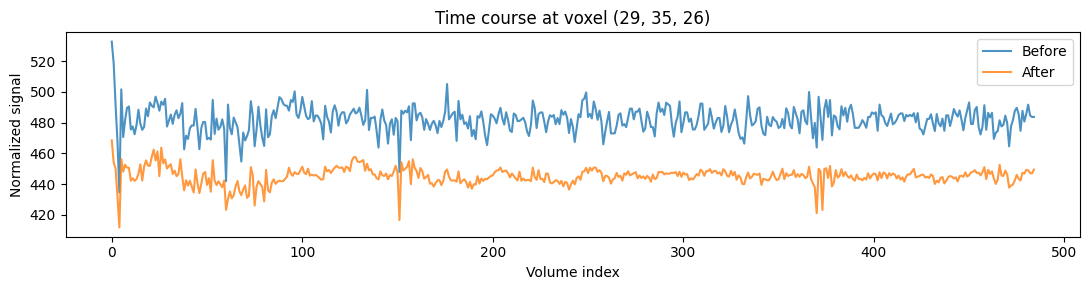

In [44]:
t = min(max(int(PREVIEW_VOLUME), 0), before.shape[3] - 1)
z = int(np.argmax(brain_support.sum(axis=(0, 1))))
slice_support = brain_support[:, :, z]
finite_slice = before[:, :, z, t][slice_support]
vmin, vmax = np.percentile(finite_slice, [2, 98])
if vmax <= vmin:
    vmin, vmax = float(vmin - 1e-6), float(vmax + 1e-6)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, data, title in [(axes[0], before, 'Before'), (axes[1], after, 'After')]:
    ax.imshow(data[:, :, z, t].T, origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
    ax.set_title(f'{title}: volume {t}, slice {z}'); ax.axis('off')
delta = after[:, :, z, t] - before[:, :, z, t]
limit = max(float(np.max(np.abs(delta))), 1e-6)
im = axes[2].imshow(delta.T, origin='lower', cmap='coolwarm', vmin=-limit, vmax=limit)
axes[2].set_title('After minus before'); axes[2].axis('off')
fig.colorbar(im, ax=axes[2], shrink=0.7)
plt.tight_layout(); plt.show()

coordinates = np.argwhere(slice_support)
centre = coordinates.mean(axis=0)
xy = coordinates[np.argmin(np.sum((coordinates-centre)**2, axis=1))]
voxel = (int(xy[0]), int(xy[1]), z)
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(before[voxel], label='Before', alpha=0.8)
ax.plot(after[voxel], label='After', alpha=0.8)
ax.set(xlabel='Volume index', ylabel='Normalized signal', title=f'Time course at voxel {voxel}')
ax.legend(); plt.tight_layout(); plt.show()

## 10. Optional: remaining selected video runs for this subject
After inspecting the first run, execute `RUN_REMAINING_VIDEO_RUNS = True` in a new cell, then execute the next cell. It uses only the previously displayed selected files and skips the first run already processed in this session. You do not need to rerun the earlier processing cell.

If restarting the kernel, existing saved outputs trigger overwrite protection. To rerun them, explicitly enable `OVERWRITE=True`, or choose another output directory. If changing subject, tasks or smoothing settings, restart the workflow so selections and paths stay consistent.

In [ ]:
if RUN_REMAINING_VIDEO_RUNS:
    done = {r['source'] for r in records}
    for f in selected_files:
        if str(Path(f.path).resolve()) in done:
            continue
        print('Smoothing:', Path(f.path).name)
        record = smooth_one_run(f.path, DATA_ROOT, OUTPUT_ROOT, FWHM_MM,
                                preserve_zero_background=PRESERVE_ZERO_BACKGROUND,
                                overwrite=OVERWRITE)
        records.append(record)
        done.add(record['source'])
else:
    print('Only the first video run processed. Remaining-run processing is disabled.')
report = pd.DataFrame(records)
report_path = run_output_root / f'sub-{SUBJECT}_smoothing_report.tsv'
report.to_csv(report_path, sep='\t', index=False)
display(report)
print('Report:', report_path)

## Next: reuse in a Python script
Move `output_path_for` and `smooth_one_run` into your future `.py` file and keep the single-subject BIDS query. Notebook `%pip` is not Python-script syntax. No all-subject loop is included here.

For input-versus-output ISC comparisons, apply the same chosen smoothing settings to both conditions in separate output directories. Retain unsmoothed data and avoid applying smoothing twice inadvertently. Smoothing time series before ISC differs from smoothing ISC maps after calculation.

**Verification status:** the notebook structure and Python syntax can be checked where it was prepared, but your Lustre dataset is not accessible there. The real-file checks in section 8 run only when you execute this notebook on the cluster.

### Documentation
- [Nilearn smooth_img](https://nilearn.github.io/stable/modules/generated/nilearn.image.smooth_img.html): Gaussian filtering over the first three dimensions and FWHM in millimetres.
- [PyBIDS tutorial](https://bids-standard.github.io/pybids/examples/pybids_tutorial.html): selecting files by subject/task/run.
- [PyBIDS BIDSLayout](https://bids-standard.github.io/pybids/generated/bids.layout.BIDSLayout.html): dataset indexing.